In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('placement-dataset.csv')

In [3]:
df

,city,cgpa,iq,placement
0,New York,6.8,123.0,1
1,Los Angeles,5.9,106.0,0
2,Chicago,NaN,121.0,0
3,New York,7.4,132.0,1
4,Los Angeles,5.8,142.0,0
...,...,...,...,...
95,Chicago,4.3,200.0,0
96,New York,4.4,42.0,0
97,Los Angeles,6.7,182.0,1
98,Chicago,6.3,103.0,1


In [4]:
df = df.iloc[:, 1:]

In [5]:
df

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,NaN,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0
...,...,...,...
95,4.3,200.0,0
96,4.4,42.0,0
97,6.7,182.0,1
98,6.3,103.0,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       92 non-null     float64
 1   iq         96 non-null     float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [7]:
df['cgpa'] = df['cgpa'].fillna(df['cgpa'].median())
df['iq'] = df['iq'].fillna(df['iq'].median())

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


# Steps:

### 0. Preprocess + EDA + Feature Selection
1. Extract input and output cols
2. Scale the values
3. Train test split
4. Train the model
5. Evaluate the model/model selection
6. Deploy the model

In [9]:
import matplotlib.pyplot as plt

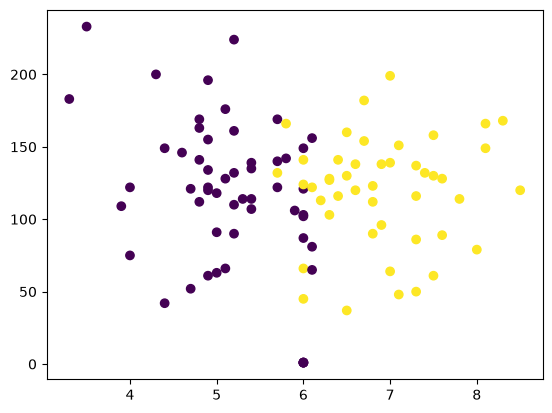

In [10]:
plt.scatter(df['cgpa'], df['iq'], c = df['placement'])

In [11]:
X = df.iloc[:, 0:2]
Y = df.iloc[:, -1]

In [12]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,6.0,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [13]:
Y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [14]:
Y.shape

(100,)

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.1)

In [16]:
X_train

,cgpa,iq
31,3.9,109.0
61,7.3,137.0
6,5.7,122.0
58,8.0,79.0
43,6.0,141.0
...,...,...
53,8.3,168.0
60,6.0,1.0
44,7.5,61.0
52,6.0,1.0


In [17]:
X_test

,cgpa,iq
89,4.9,122.0
68,4.0,75.0
2,6.0,121.0
82,6.5,37.0
65,8.1,166.0
15,5.1,176.0
41,5.4,114.0
85,5.8,166.0
12,5.4,139.0
20,6.6,120.0


In [18]:
Y_train

31    0
61    1
6     0
58    1
43    1
     ..
53    1
60    0
44    1
52    0
57    1
Name: placement, Length: 90, dtype: int64

In [19]:
Y_test

89    0
68    0
2     0
82    1
65    1
15    0
41    0
85    1
12    0
20    1
Name: placement, dtype: int64

In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()

In [22]:
X_train = scaler.fit_transform(X_train)

In [23]:
X_train

array([[-1.8742921 , -0.18318739],
       [ 1.17641738,  0.42262917],
       [-0.25921061,  0.09808459],
       [ 1.80450463, -0.83227656],
       [ 0.00996964,  0.5091744 ],
       [-0.70784436,  0.94190051],
       [ 0.00996964, -0.65918612],
       [ 0.90723713,  0.46590178],
       [-0.70784436, -0.16155108],
       [-1.78456535,  0.09808459],
       [-1.1564781 , -1.41645682],
       [ 0.72778363, -0.5942772 ],
       [ 0.00996964, -2.51990841],
       [-0.70784436, -0.5942772 ],
       [ 0.09969639, -0.78900395],
       [-1.24620485,  0.61735593],
       [ 1.89423138,  0.68226484],
       [ 0.27914989,  0.20626612],
       [-0.88729786, -1.17845746],
       [-0.97702461,  0.05481197],
       [ 0.00996964,  0.68226484],
       [ 1.35587088,  0.27117503],
       [-0.79757111,  0.22790242],
       [ 0.99696388,  0.72553745],
       [ 1.35587088,  0.87699159],
       [-1.5153851 ,  1.78571644],
       [-0.97702461, -1.22173007],
       [-1.42565835, -1.63281988],
       [-0.61811761,

In [24]:
X_test = scaler.fit_transform(X_test)

In [25]:
X_test

array([[-0.82724891, -0.0393245 ],
       [-1.67329893, -1.19448183],
       [ 0.20681223, -0.06390232],
       [ 0.67684002, -2.12843881],
       [ 2.18092894,  1.04209937],
       [-0.63923779,  1.28787753],
       [-0.35722112, -0.23594703],
       [ 0.01880111,  1.04209937],
       [-0.35722112,  0.37849836],
       [ 0.77084557, -0.08848014]])

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
clf = LogisticRegression()

In [28]:
# Model training
clf.fit(X_train, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [29]:
Y_pred = clf.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score

In [32]:
accuracy_score(Y_test, Y_pred)

0.9

In [34]:
!pip install mlxtend

In [33]:
import mlxtend
from mlxtend.plotting import plot_decision_regions

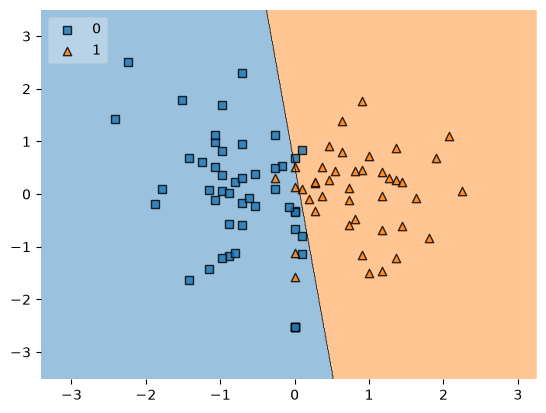

In [37]:
fig = plot_decision_regions(X_train, Y_train.values, clf=clf, legend=2)

In [38]:
import pickle

In [39]:
pickle.dump(clf, open('model.pkl', 'wb'))